# Saudi real estate prices by property type and region

**Which kinds of property and which regions of Saudi Arabia got more or less expensive in the year to Q2 2026?**

Data: General Authority for Statistics (GASTAT) Real Estate Price Index, base 2023 = 100, Q3 2024 to Q2 2026, with the national index back to Q1 2021. Every figure was collected from GASTAT reports and news reports of the same releases (`data/raw/price_index_readings.csv`). The build script `scripts/build_data.py` consolidates the readings and checks them; this notebook recomputes the headline figures from the processed tables and checks that they match.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("../data/raw/price_index_readings.csv")
sources = pd.read_csv("../data/raw/sources.csv")
tidy = pd.read_csv("../data/processed/price_index_tidy.csv")
nat = pd.read_csv("../data/processed/national_index.csv")
seg = pd.read_csv("../data/processed/segment_changes.csv")
reg = pd.read_csv("../data/processed/region_index.csv")
checks = pd.read_csv("../data/processed/identity_checks.csv")
head = pd.read_csv("../data/processed/headline_figures.csv").set_index("measure")["value"]
print(f"{len(raw)} readings from {raw.source_id.nunique()} documents by {sources.publisher.nunique()} publishers")
print(f"{len(tidy)} figures after consolidation")

725 readings from 26 documents by 9 publishers
424 figures after consolidation


## Data checks

In [2]:
set_aside = raw[raw.note.fillna("").str.startswith("set aside")]
print("Readings set aside, with the reason:")
for _, r in set_aside.iterrows():
    print(f"  {r.source_id} {r.period} {r.geography} {r.segment} {r.measure} = {r.value}: {r.note[11:]}")
print()
print("Duplicate figures in the tidy table:", tidy.duplicated(["period", "geography", "segment", "measure"]).sum())
print("Missing values in the tidy table:", int(tidy.value.isna().sum()))
print("Regions:", reg.region.nunique(), "| quarters with regional data:", reg.period.nunique())
print("Annual change range (%):", tidy[tidy.measure == "yoy"].value.min(), "to", tidy[tidy.measure == "yoy"].value.max())
print()
print("Identity checks (all must pass):")
checks.groupby("check").passed.agg(["size", "sum"])

Readings set aside, with the reason:
  S1 Q4 2024 Saudi Arabia agricultural qoq = -9.8: the minus sign comes from the PDF text extraction; agricultural levels (Q3 2024 implied 95.6 from Q3 2025 110.2 at +15.3%, Q4 2024 104.9) give +9.8, as printed by Economy Middle East
  S1 Q4 2024 Saudi Arabia agricultural_land qoq = -9.8: the minus sign comes from the PDF text extraction; agricultural levels (Q3 2024 implied 95.6 from Q3 2025 110.2 at +15.3%, Q4 2024 104.9) give +9.8, as printed by Economy Middle East
  A2 Q4 2024 Makkah all yoy = -0.6: GASTAT's own Q4 2024 report prints -0.5; the official figure is used
  E2 Q2 2025 Saudi Arabia commercial_land yoy = 12.6: GASTAT's own Q2 2025 report prints 12.7; the official figure is used
  O1 Q3 2025 Saudi Arabia all yoy = -1.3: sign does not match the article wording or other reports; Argaam, Enterprise and Trading Economics print +1.3 and the quarterly changes chain to +1.3
  T1 Q1 2026 Saudi Arabia all qoq = -0.4: GASTAT's Q1 2026 report, Ent

,size,sum
check,,
qoq from levels,13,13
yoy from four qoq,22,22
yoy from levels,57,57


In [3]:
# Coverage: how many of the 13 regions have an annual change in each quarter
reg.groupby("period", sort=False).yoy_pct.count().rename("regions_with_annual_change")

period
Q3 2024    13
Q4 2024    13
Q1 2025    13
Q2 2025    13
Q3 2025    13
Q4 2025    13
Q1 2026    13
Q2 2026     8
Name: regions_with_annual_change, dtype: int64

In [4]:
# How the figures are confirmed
tidy.pivot_table(index="measure", columns="source_check", values="value", aggfunc="size", fill_value=0)

source_check,derived,one-document,same-publisher,two-publishers
measure,,,,
level,10,118,5,0
qoq,0,42,0,29
weight,0,21,0,1
yoy,0,67,0,131


## Recompute the headline figures and compare with the build script

In [5]:
def val(measure, period, segment="all", geo="Saudi Arabia"):
    r = tidy[(tidy.measure == measure) & (tidy.period == period) & (tidy.segment == segment) & (tidy.geography == geo)]
    assert len(r) == 1, (measure, period, segment, geo)
    return float(r.value.iloc[0])

level_q1 = val("level", "Q1 2026")
level_q2 = round(level_q1 * (1 + val("qoq", "Q2 2026") / 100), 2)
level_q2_alt = val("level", "Q2 2025") * (1 + val("yoy", "Q2 2026") / 100)
assert abs(level_q2 - level_q2_alt) < 0.15

latest = seg[(seg.period == "Q2 2026") & ~seg.segment.isin(["all", "residential", "commercial", "agricultural"])]
q1 = reg[reg.period == "Q1 2026"].set_index("region")
q3 = reg[reg.period == "Q3 2024"].set_index("region")
q2r = reg[(reg.period == "Q2 2026") & reg.yoy_pct.notna()].set_index("region")
six = ((q1.index_level / q3.index_level - 1) * 100).round(1)

mine = {
    "national_level_q2_2026_derived": level_q2,
    "national_yoy_q2_2026": val("yoy", "Q2 2026"),
    "national_qoq_q2_2026": val("qoq", "Q2 2026"),
    "national_yoy_q4_2025": val("yoy", "Q4 2025"),
    "national_yoy_q1_2026": val("yoy", "Q1 2026"),
    "villa_yoy_q2_2026": val("yoy", "Q2 2026", "villa"),
    "villa_yoy_q1_2025": val("yoy", "Q1 2025", "villa"),
    "residential_land_yoy_q2_2026": val("yoy", "Q2 2026", "residential_land"),
    "apartment_yoy_q2_2026": val("yoy", "Q2 2026", "apartment"),
    "commercial_yoy_q2_2026": val("yoy", "Q2 2026", "commercial"),
    "residential_yoy_q2_2026": val("yoy", "Q2 2026", "residential"),
    "subsector_lowest_q2_2026": latest.set_index("segment").yoy_pct.idxmin(),
    "subsector_highest_q2_2026": latest.set_index("segment").yoy_pct.idxmax(),
    "regions_q1_2026_count": int(q1.yoy_pct.notna().sum()),
    "regions_q1_2026_rising": int((q1.yoy_pct > 0).sum()),
    "region_q1_2026_highest": q1.yoy_pct.idxmax(),
    "region_q1_2026_highest_pct": q1.yoy_pct.max(),
    "region_q1_2026_lowest": q1.yoy_pct.idxmin(),
    "region_q1_2026_lowest_pct": q1.yoy_pct.min(),
    "regions_q2_2026_published": len(q2r),
    "region_q2_2026_highest": q2r.yoy_pct.idxmax(),
    "region_q2_2026_highest_pct": q2r.yoy_pct.max(),
    "region_q2_2026_lowest": q2r.yoy_pct.idxmin(),
    "region_q2_2026_lowest_pct": q2r.yoy_pct.min(),
    "riyadh_level_q3_2024": q3.loc["Riyadh", "index_level"],
    "riyadh_level_q1_2026": q1.loc["Riyadh", "index_level"],
    "riyadh_yoy_q2_2026": q2r.loc["Riyadh", "yoy_pct"],
    "change_6q_highest_region": six.idxmax(),
    "change_6q_highest_pct": six.max(),
    "change_6q_lowest_region": six.idxmin(),
    "change_6q_lowest_pct": six.min(),
    "identity_checks_run": len(checks),
    "readings": len(raw),
    "readings_set_aside": len(set_aside),
}
for k, v in mine.items():
    b = head[k]
    try:
        assert abs(float(v) - float(b)) < 1e-6, (k, v, b)
    except ValueError:
        assert str(v) == str(b), (k, v, b)
print(f"All {len(mine)} headline figures match the build script output.")
pd.Series(mine, name="value").to_frame()

All 34 headline figures match the build script output.


,value
national_level_q2_2026_derived,106.4
national_yoy_q2_2026,1.3
national_qoq_q2_2026,3.0
national_yoy_q4_2025,-0.7
national_yoy_q1_2026,-1.6
villa_yoy_q2_2026,-9.7
villa_yoy_q1_2025,10.3
residential_land_yoy_q2_2026,6.3
apartment_yoy_q2_2026,1.1
commercial_yoy_q2_2026,-3.2


## 1. The national index

In [6]:
nat.tail(9)

,period,index_level,level_basis,yoy_pct,qoq_pct
13,Q2 2024,101.79,printed,1.6,NaN
14,Q3 2024,102.50,printed,2.6,NaN
15,Q4 2024,104.18,printed,3.6,1.6
16,Q1 2025,104.93,printed,4.3,0.7
17,Q2 2025,105.00,printed,3.2,0.1
18,Q3 2025,103.90,derived,1.3,-1.1
19,Q4 2025,103.48,printed,-0.7,-0.4
20,Q1 2026,103.30,printed,-1.6,-0.2
21,Q2 2026,106.40,derived,1.3,3.0


The index rose 1.3% on the year to Q2 2026 after two quarters of annual decline (-0.7% in Q4 2025, -1.6% in Q1 2026). On the quarter it rose 3.0%, to a derived level of 106.4 (2023 = 100). The Q2 2026 and Q3 2025 levels are not printed in any document found; they are computed from a printed level and a printed change, and both routes agree.

## 2. Property types in Q2 2026

In [7]:
latest.sort_values("yoy_pct")[["segment_label", "weight_pct", "yoy_pct", "qoq_pct", "yoy_source_check"]]

,segment_label,weight_pct,yoy_pct,qoq_pct,yoy_source_check
91,Villas,10.5,-9.7,-2.1,two-publishers
86,Commercial land,22.8,-3.5,NaN,two-publishers
85,Commercial buildings,2.0,-0.6,-0.3,two-publishers
87,Residential floors,1.4,0.4,-1.1,two-publishers
90,Showrooms and shops,0.6,0.4,3.8,two-publishers
83,Apartments,15.0,1.1,0.9,two-publishers
89,Residential land,45.8,6.3,6.1,two-publishers
81,Agricultural land,1.9,11.3,NaN,two-publishers


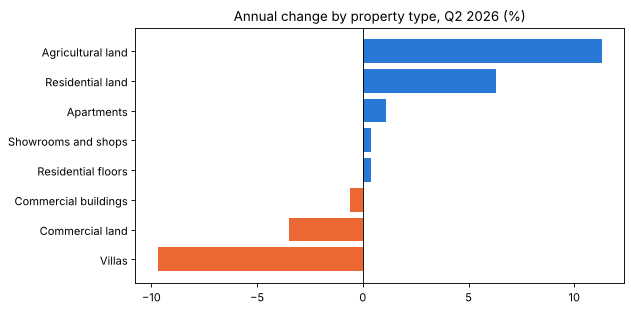

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
d = latest.sort_values("yoy_pct")
ax.barh(d.segment_label, d.yoy_pct, color=["#eb6834" if v < 0 else "#2a78d6" for v in d.yoy_pct])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Annual change by property type, Q2 2026 (%)")
plt.tight_layout()

In [9]:
# Gap between the fastest- and slowest-moving property type in each quarter
sub = seg[~seg.segment.isin(["all", "residential", "commercial", "agricultural"])]
gap = sub.groupby("period", sort=False).yoy_pct.agg(["max", "min"])
gap["gap"] = (gap["max"] - gap["min"]).round(1)
gap

,max,min,gap
period,,,
Q3 2024,8.6,-8.7,17.3
Q4 2024,6.5,-1.7,8.2
Q1 2025,10.3,1.2,9.1
Q2 2025,12.7,-0.7,13.4
Q3 2025,7.2,-1.7,8.9
Q4 2025,3.5,-2.5,6.0
Q1 2026,11.8,-6.1,17.9
Q2 2026,11.3,-9.7,21.0


## 3. Villas, residential land and apartments over eight quarters

In [10]:
trend = seg[seg.segment.isin(["villa", "residential_land", "apartment", "all"])].pivot(index="period", columns="segment", values="yoy_pct")
trend = trend.loc[list(dict.fromkeys(seg.period))]
trend

segment,all,apartment,residential_land,villa
period,,,,
Q3 2024,2.6,1.9,1.6,1.5
Q4 2024,3.6,2.9,2.5,6.5
Q1 2025,4.3,1.2,5.3,10.3
Q2 2025,3.2,-0.7,0.2,3.2
Q3 2025,1.3,-1.7,-0.9,0.2
Q4 2025,-0.7,-2.5,-2.4,-1.3
Q1 2026,-1.6,-1.1,-3.9,-6.1
Q2 2026,1.3,1.1,6.3,-9.7


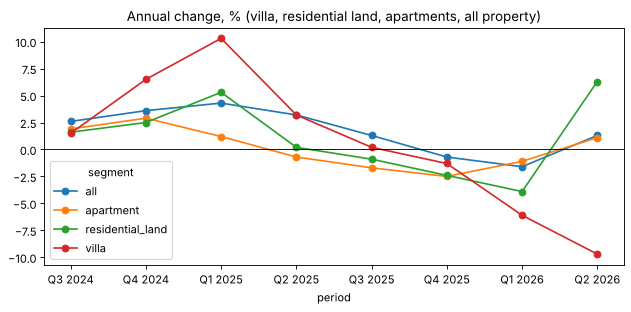

In [11]:
ax = trend.plot(figsize=(8, 4), marker="o")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Annual change, % (villa, residential land, apartments, all property)")
plt.tight_layout()

## 4. Regions

In [12]:
q1.sort_values("yoy_pct", ascending=False)[["index_level", "yoy_pct", "yoy_source_check"]]

,index_level,yoy_pct,yoy_source_check
region,,,
Eastern,97.8,6.9,two-publishers
Najran,105.6,3.5,two-publishers
Tabuk,102.0,1.5,two-publishers
Asir,88.5,1.1,two-publishers
Makkah,99.4,-0.7,two-publishers
Al Jouf,95.6,-1.4,one-document
Jazan,100.3,-1.4,one-document
Riyadh,109.8,-4.4,two-publishers
Madinah,93.6,-5.0,one-document


In [13]:
pd.DataFrame({"level_q3_2024": q3.index_level, "level_q1_2026": q1.index_level, "change_pct": six}).sort_values("change_pct", ascending=False)

,level_q3_2024,level_q1_2026,change_pct
region,,,
Najran,97.8,105.6,8.0
Eastern,92.0,97.8,6.3
Tabuk,100.2,102.0,1.8
Makkah,98.6,99.4,0.8
Jazan,100.3,100.3,0.0
Riyadh,109.8,109.8,0.0
Northern Borders,101.8,100.0,-1.8
Al Jouf,98.1,95.6,-2.5
Asir,92.4,88.5,-4.2


In [14]:
q2r.sort_values("yoy_pct", ascending=False)[["index_level", "level_basis", "yoy_pct", "yoy_source_check"]]

,index_level,level_basis,yoy_pct,yoy_source_check
region,,,,
Al Jouf,107.01,derived,10.4,two-publishers
Northern Borders,103.86,derived,4.6,two-publishers
Riyadh,116.03,derived,4.2,two-publishers
Makkah,102.48,derived,0.4,two-publishers
Al Baha,77.92,derived,-2.8,two-publishers
Madinah,91.71,derived,-4.5,two-publishers
Qassim,92.22,derived,-5.4,two-publishers
Hail,92.28,derived,-10.1,two-publishers


Q2 2026 regional levels are derived from the Q2 2025 level and the reported annual change. Five regions (Eastern, Najran, Tabuk, Asir, Jazan) have no Q2 2026 figure in any report found, so the latest complete regional comparison is Q1 2026.